# Notebook 05 - Evaluierung
### LSTM (fine-tuned) vs TFT (fine-tuned) vs Ablation (ohne Pre-Training)

Nutzt die von Notebook 03/04 gespeicherten Feature-Listen
(lstm_feature_cols_common.pkl / tft_feature_cols_common.pkl) statt
diese neu zu berechnen - vermeidet Inkonsistenzen bei Aenderungen am
Feature-Set.

In [1]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 1: Imports & Daten laden
# ═══════════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pickle
import warnings
warnings.filterwarnings('ignore')

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pytorch_forecasting import TemporalFusionTransformer, TimeSeriesDataSet

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {device}')

train   = pd.read_csv('../data/final/train.csv')
train['plr_id'] = train['plr_id'].astype(str).str.zfill(8)
val     = pd.read_csv('../data/final/val.csv')
val['plr_id'] = val['plr_id'].astype(str).str.zfill(8)
test    = pd.read_csv('../data/final/test.csv')
test['plr_id'] = test['plr_id'].astype(str).str.zfill(8)
df_full_raw = pd.read_csv('../data/final/df_full.csv')
df_full_raw['plr_id'] = df_full_raw['plr_id'].astype(str).str.zfill(8)

with open('../models/feature_cols.pkl', 'rb') as f:
    FEATURE_COLS = pickle.load(f)
with open('../models/target.pkl', 'rb') as f:
    TARGET = pickle.load(f)
with open('../models/meta.pkl', 'rb') as f:
    meta = pickle.load(f)

SEQ_LEN = meta.get('seq_len', 3)
ALLE_JAHRE_META = [int(y) for y in meta.get('jahre', [])]

# Vollstaendigkeits-Filter: nur PLR mit allen Anker-Jahren behalten
required_years = set(ALLE_JAHRE_META) if ALLE_JAHRE_META else set(df_full_raw['year'].unique())
jahre_pro_plr = df_full_raw.groupby('plr_id')['year'].apply(lambda s: set(int(y) for y in s))
vollstaendige_plr = jahre_pro_plr[jahre_pro_plr.apply(lambda s: required_years.issubset(s))].index
df_full = df_full_raw[df_full_raw['plr_id'].isin(vollstaendige_plr)].copy()

# Feature-Listen: bevorzugt die von Notebook 03/04 gespeicherten
# tatsaechlich verwendeten Listen laden (verhindert Rate-/Annahme-Fehler)
import os
if os.path.exists('../models/lstm_feature_cols_common.pkl'):
    with open('../models/lstm_feature_cols_common.pkl', 'rb') as f:
        FEATURE_COLS_LSTM = pickle.load(f)
else:
    FEATURE_COLS_LSTM = FEATURE_COLS

if os.path.exists('../models/tft_feature_cols_common.pkl'):
    with open('../models/tft_feature_cols_common.pkl', 'rb') as f:
        FEATURE_COLS_TFT = pickle.load(f)
else:
    FEATURE_COLS_TFT = FEATURE_COLS

print(f'ECHTE Testdaten: {len(test)} Zeilen | Ziel: {TARGET}')
print(f'Features (gesamt):     {FEATURE_COLS}')
print(f'Features (LSTM-Modell): {FEATURE_COLS_LSTM}')
print(f'Features (TFT-Modell):  {FEATURE_COLS_TFT}')
print(f'SEQ_LEN: {SEQ_LEN} | Anker-Jahre: {sorted(required_years)}')
print(f'PLR mit vollstaendiger Zeitreihe: {len(vollstaendige_plr)} von {df_full_raw["plr_id"].nunique()}')

Device: mps
ECHTE Testdaten: 540 Zeilen | Ziel: status_next
Features (gesamt):     ['arbeitslosigkeit', 'sgb2_quote', 'kinderarmut', 'dist_zentrum', 'status_lag']
Features (LSTM-Modell): ['arbeitslosigkeit', 'sgb2_quote', 'kinderarmut', 'dist_zentrum', 'status_lag']
Features (TFT-Modell):  ['arbeitslosigkeit', 'sgb2_quote', 'kinderarmut', 'dist_zentrum', 'status_lag']
SEQ_LEN: 3 | Anker-Jahre: [2013, 2015, 2017, 2019, 2021, 2023]
PLR mit vollstaendiger Zeitreihe: 519 von 541


In [2]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 2: Klassen & Metrik-Funktion
# ═══════════════════════════════════════════════════════════════

class BerlinDataset(Dataset):
    def __init__(self, df_full, feature_cols, target_col, seq_len=3, target_years=None):
        self.sequences, self.targets, self.plr_ids = [], [], []
        if target_years is not None:
            target_years = set(int(y) for y in target_years)
        for plr_id, group in df_full.groupby('plr_id'):
            group = group.sort_values('year').reset_index(drop=True)
            X = group[feature_cols].values.astype(np.float32)
            y = group[target_col].values.astype(np.float32)
            yrs = group['year'].values
            for i in range(len(group) - seq_len):
                target_yr = int(yrs[i + seq_len])
                if target_years is None or target_yr in target_years:
                    self.sequences.append(X[i:i+seq_len])
                    self.targets.append(y[i+seq_len])
                    self.plr_ids.append(str(plr_id))
        if len(self.sequences) > 0:
            self.sequences = torch.FloatTensor(np.array(self.sequences))
            self.targets   = torch.FloatTensor(np.array(self.targets))
        else:
            self.sequences = torch.zeros(0, seq_len, len(feature_cols))
            self.targets   = torch.zeros(0)
    def __len__(self): return len(self.targets)
    def __getitem__(self, idx): return self.sequences[idx], self.targets[idx]


class BerlinLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=32, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            dropout=0.2, batch_first=True)
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 16), nn.ReLU(),
            nn.Dropout(0.2), nn.Linear(16, 1)
        )
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])


def metriken(y_true, y_pred, name):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    baseline_mae = mean_absolute_error(y_true, np.full_like(y_true, y_true.mean()))
    improvement = (1 - mae/baseline_mae) * 100 if baseline_mae > 0 else 0
    print(f"\n{'='*42}\n  {name}\n{'='*42}")
    print(f'  MAE:          {mae:.4f}')
    print(f'  RMSE:         {rmse:.4f}')
    print(f'  R²:           {r2:.4f}')
    print(f'  Baseline MAE: {baseline_mae:.4f}')
    print(f'  Verbesserung: {improvement:.1f}%')
    return {'Modell': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2, 'Verbesserung_%': improvement}

print('✅ Klassen definiert!')

✅ Klassen definiert!


In [3]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 3: LSTM Vorhersagen (Fine-Tuned + Ablation)
# ═══════════════════════════════════════════════════════════════

TEST_YEARS = [int(y) for y in test['year'].unique()]

test_set = BerlinDataset(df_full, FEATURE_COLS_LSTM, TARGET, SEQ_LEN, TEST_YEARS)
test_dl  = DataLoader(test_set, batch_size=16, shuffle=False)
print(f'Test Sequenzen: {len(test_set)}')

def lstm_predict(model_path, dataloader, n_features):
    model = BerlinLSTM(input_size=n_features).to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    preds, actuals = [], []
    with torch.no_grad():
        for X, y in dataloader:
            X = X.to(device)
            pred = model(X)
            preds.extend(pred.cpu().numpy().flatten().tolist())
            actuals.extend(y.numpy().tolist())
    return np.array(preds), np.array(actuals)

N_FEATURES_LSTM = len(FEATURE_COLS_LSTM)

lstm_ft_preds, actuals = lstm_predict(
    '../models/lstm_finetuned.pt', test_dl, N_FEATURES_LSTM)
print(f'✅ LSTM (fine-tuned): {lstm_ft_preds.shape} Vorhersagen')

if os.path.exists('../models/lstm_scratch.pt'):
    lstm_scratch_preds, _ = lstm_predict(
        '../models/lstm_scratch.pt', test_dl, N_FEATURES_LSTM)
    print(f'✅ LSTM (ohne Pre-Training): {lstm_scratch_preds.shape} Vorhersagen')
    HAS_ABLATION = True
else:
    HAS_ABLATION = False
    print('⚠️ Kein Ablationsmodell gefunden - ueberspringe Vergleich')

Test Sequenzen: 519
✅ LSTM (fine-tuned): (519,) Vorhersagen
✅ LSTM (ohne Pre-Training): (519,) Vorhersagen


In [4]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 4: TFT Vorhersagen (Fine-Tuned)
# ═══════════════════════════════════════════════════════════════

df_tft_raw = pd.read_csv('../data/final/df_full.csv')
df_tft_raw['plr_id'] = df_tft_raw['plr_id'].astype(str).str.zfill(8)
df_tft_raw = df_tft_raw.sort_values(['plr_id', 'year']).reset_index(drop=True)

jahre_pro_plr_tft = df_tft_raw.groupby('plr_id')['year'].apply(lambda s: set(int(y) for y in s))
vollstaendige_plr_tft = jahre_pro_plr_tft[
    jahre_pro_plr_tft.apply(lambda s: required_years.issubset(s))
].index
df_tft = df_tft_raw[df_tft_raw['plr_id'].isin(vollstaendige_plr_tft)].copy()

print(f'PLR mit vollstaendiger Zeitreihe (TFT): {len(vollstaendige_plr_tft)} '
      f'von {df_tft_raw["plr_id"].nunique()}')

year_map = {y: i for i, y in enumerate(sorted(df_tft['year'].unique()))}
df_tft['time_idx'] = df_tft['year'].map(year_map)

train_years_set = set(int(y) for y in train['year'].unique())
training_cutoff = df_tft[df_tft['year'].isin(train_years_set)]['time_idx'].max()

train_ds = TimeSeriesDataSet(
    df_tft[df_tft['time_idx'] <= training_cutoff],
    time_idx='time_idx', target=TARGET, group_ids=['plr_id'],
    max_encoder_length=SEQ_LEN, max_prediction_length=1,
    time_varying_known_reals=['time_idx'],
    time_varying_unknown_reals=FEATURE_COLS_TFT,  # OPTION B: TARGET entfernt
    static_reals=['dist_zentrum'],
    target_normalizer=None, add_relative_time_idx=True,
    allow_missing_timesteps=True,
)
test_ds = TimeSeriesDataSet.from_dataset(train_ds, df_tft, predict=True, stop_randomization=True)
tft_dl = test_ds.to_dataloader(train=False, batch_size=32, num_workers=0)

print(f'✅ TFT Test Dataset: {len(test_ds)} Samples')

with open('../models/tft_checkpoint_path.pkl', 'rb') as f:
    tft_ckpt_path = pickle.load(f)

best_tft = TemporalFusionTransformer.load_from_checkpoint(tft_ckpt_path)
tft_preds = best_tft.predict(tft_dl, trainer_kwargs=dict(accelerator='mps')).numpy().flatten()

print(f'✅ TFT (fine-tuned): {tft_preds.shape} Vorhersagen')

PLR mit vollstaendiger Zeitreihe (TFT): 519 von 541
✅ TFT Test Dataset: 519 Samples


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


✅ TFT (fine-tuned): (519,) Vorhersagen


In [5]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 5: Metriken & Ablationsvergleich
# ═══════════════════════════════════════════════════════════════

n = min(len(actuals), len(tft_preds))
actuals_n, tft_preds_n = actuals[:n], tft_preds[:n]

results = []
results.append(metriken(actuals, lstm_ft_preds, 'LSTM (fine-tuned)'))
results.append(metriken(actuals_n, tft_preds_n, 'TFT (fine-tuned)'))
if HAS_ABLATION:
    results.append(metriken(actuals, lstm_scratch_preds, 'LSTM (ohne Pre-Training)'))

results_df = pd.DataFrame(results)
print('\n📊 Gesamtvergleich:')
print(results_df.to_string(index=False))
results_df.to_csv('../results/modellvergleich.csv', index=False)
print('\n✅ Modellvergleich gespeichert!')


  LSTM (fine-tuned)
  MAE:          0.3345
  RMSE:         0.4467
  R²:           0.5811
  Baseline MAE: 0.5756
  Verbesserung: 41.9%

  TFT (fine-tuned)
  MAE:          0.1655
  RMSE:         0.2396
  R²:           0.8795
  Baseline MAE: 0.5756
  Verbesserung: 71.2%

  LSTM (ohne Pre-Training)
  MAE:          0.1526
  RMSE:         0.2130
  R²:           0.9048
  Baseline MAE: 0.5756
  Verbesserung: 73.5%

📊 Gesamtvergleich:
                  Modell      MAE     RMSE       R2  Verbesserung_%
       LSTM (fine-tuned) 0.334542 0.446742 0.581106       41.881597
        TFT (fine-tuned) 0.165525 0.239601 0.879505       71.244139
LSTM (ohne Pre-Training) 0.152622 0.212984 0.904790       73.485737

✅ Modellvergleich gespeichert!


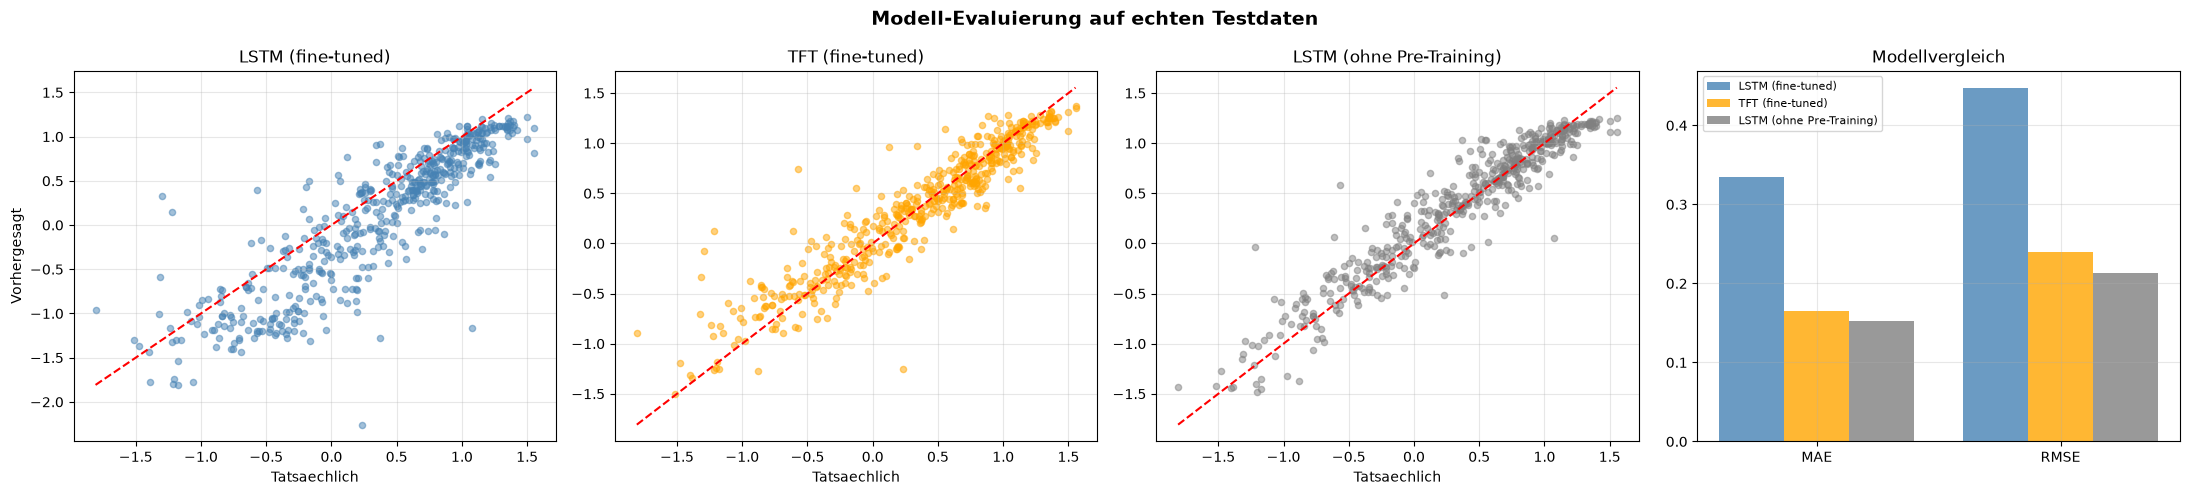

✅ NOTEBOOK 05 ABGESCHLOSSEN!

📊 Finale Ergebnisse:
                  Modell      MAE     RMSE       R2  Verbesserung_%
       LSTM (fine-tuned) 0.334542 0.446742 0.581106       41.881597
        TFT (fine-tuned) 0.165525 0.239601 0.879505       71.244139
LSTM (ohne Pre-Training) 0.152622 0.212984 0.904790       73.485737

🏆 Bestes Modell (MAE): LSTM (ohne Pre-Training)

→ Weiter mit Notebook 06 (SHAP - NUR auf echten Daten & Fine-Tuned-Modell!)


In [6]:
# ═══════════════════════════════════════════════════════════════
# ZELLE 6: Visualisierungen
# ═══════════════════════════════════════════════════════════════

n_plots = 4 if HAS_ABLATION else 3
fig, axes = plt.subplots(1, n_plots, figsize=(5.5*n_plots, 5))
fig.suptitle('Modell-Evaluierung auf echten Testdaten', fontsize=14, fontweight='bold')

axes[0].scatter(actuals, lstm_ft_preds, alpha=0.5, color='steelblue', s=20)
axes[0].plot([actuals.min(), actuals.max()], [actuals.min(), actuals.max()], 'r--')
axes[0].set_title('LSTM (fine-tuned)'); axes[0].set_xlabel('Tatsaechlich')
axes[0].set_ylabel('Vorhergesagt'); axes[0].grid(alpha=0.3)

axes[1].scatter(actuals_n, tft_preds_n, alpha=0.5, color='orange', s=20)
axes[1].plot([actuals_n.min(), actuals_n.max()], [actuals_n.min(), actuals_n.max()], 'r--')
axes[1].set_title('TFT (fine-tuned)'); axes[1].set_xlabel('Tatsaechlich')
axes[1].grid(alpha=0.3)

if HAS_ABLATION:
    axes[2].scatter(actuals, lstm_scratch_preds, alpha=0.5, color='grey', s=20)
    axes[2].plot([actuals.min(), actuals.max()], [actuals.min(), actuals.max()], 'r--')
    axes[2].set_title('LSTM (ohne Pre-Training)'); axes[2].set_xlabel('Tatsaechlich')
    axes[2].grid(alpha=0.3)
    idx_bar = 3
else:
    idx_bar = 2

metr = ['MAE', 'RMSE']
x = np.arange(len(metr))
w = 0.8 / len(results_df)
colors = ['steelblue', 'orange', 'grey']
for i, row in results_df.iterrows():
    axes[idx_bar].bar(x + i*w, [row[m] for m in metr], w,
                       label=row['Modell'], color=colors[i % 3], alpha=0.8)
axes[idx_bar].set_xticks(x + w); axes[idx_bar].set_xticklabels(metr)
axes[idx_bar].set_title('Modellvergleich'); axes[idx_bar].legend(fontsize=8)
axes[idx_bar].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../results/05_evaluierung.png', dpi=150)
plt.show()

print('✅ NOTEBOOK 05 ABGESCHLOSSEN!')
print('\n📊 Finale Ergebnisse:')
print(results_df.to_string(index=False))
best = results_df.loc[results_df['MAE'].idxmin(), 'Modell']
print(f'\n🏆 Bestes Modell (MAE): {best}')
print('\n→ Weiter mit Notebook 06 (SHAP - NUR auf echten Daten & Fine-Tuned-Modell!)')